<a href="https://colab.research.google.com/github/tanujarakeshcs24-crypto/BIS_Lab/blob/main/BISLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
#PROBLEM 1: GENETIC ALGORITHM FOR OPTIMIZATION
import random

def fitness(x):
    return x ** 2

POPULATION_SIZE = 10
CHROMOSOME_LENGTH = 5
MUTATION_RATE = 0.1
CROSSOVER_RATE = 0.8
GENERATIONS = 20

def create_population():
    return [
        [random.randint(0, 1) for _ in range(CHROMOSOME_LENGTH)]
        for _ in range(POPULATION_SIZE)
    ]

def decode(chromosome):
    return int("".join(map(str, chromosome)), 2)

def selection(population):
    parent1 = max(
        random.sample(population, 2),
        key=lambda x: fitness(decode(x))
    )
    parent2 = max(
        random.sample(population, 2),
        key=lambda x: fitness(decode(x))
    )
    return parent1, parent2

def crossover(parent1, parent2):
    if random.random() < CROSSOVER_RATE:
        point = random.randint(1, CHROMOSOME_LENGTH - 1)
        child1 = parent1[:point] + parent2[point:]
        child2 = parent2[:point] + parent1[point:]
        return child1, child2
    return parent1[:], parent2[:]

def mutation(chromosome):
    for i in range(CHROMOSOME_LENGTH):
        if random.random() < MUTATION_RATE:
            chromosome[i] = 1 - chromosome[i]
    return chromosome

population = create_population()
best_solution = None
best_fitness = float("-inf")

for generation in range(GENERATIONS):
    for individual in population:
        value = fitness(decode(individual))
        if value > best_fitness:
            best_fitness = value
            best_solution = individual[:]

    new_population = []

    while len(new_population) < POPULATION_SIZE:
        parent1, parent2 = selection(population)
        child1, child2 = crossover(parent1, parent2)
        child1 = mutation(child1)
        child2 = mutation(child2)
        new_population.extend([child1, child2])

    population = new_population[:POPULATION_SIZE]

    print(
        f"Generation {generation + 1}: "
        f"x = {decode(best_solution)}, "
        f"Fitness = {best_fitness}"
    )

print("\nBest Solution Found:")
print("x =", decode(best_solution))
print("Maximum value =", best_fitness)


Generation 1: x = 25, Fitness = 625
Generation 2: x = 27, Fitness = 729
Generation 3: x = 27, Fitness = 729
Generation 4: x = 29, Fitness = 841
Generation 5: x = 29, Fitness = 841
Generation 6: x = 30, Fitness = 900
Generation 7: x = 30, Fitness = 900
Generation 8: x = 31, Fitness = 961
Generation 9: x = 31, Fitness = 961
Generation 10: x = 31, Fitness = 961
Generation 11: x = 31, Fitness = 961
Generation 12: x = 31, Fitness = 961
Generation 13: x = 31, Fitness = 961
Generation 14: x = 31, Fitness = 961
Generation 15: x = 31, Fitness = 961
Generation 16: x = 31, Fitness = 961
Generation 17: x = 31, Fitness = 961
Generation 18: x = 31, Fitness = 961
Generation 19: x = 31, Fitness = 961
Generation 20: x = 31, Fitness = 961

Best Solution Found:
x = 31
Maximum value = 961


In [5]:
#PROBLEM 2: PARALLEL CELLULAR ALGORITHM
import random

def f(x):
    return x**2 - 4*x + 4

cells = [random.uniform(-10, 10) for _ in range(100)]

for _ in range(50):
    new_cells = []
    for x in cells:
        neighbor = max(-10, min(10, x + random.uniform(-1, 1)))
        if f(neighbor) < f(x):
            x = neighbor
        new_cells.append(x)
    cells = new_cells

best = min(cells, key=f)
worst = max(cells, key=f)

print("Minimum value:", f(best))
print("At x =", best)
print("Maximum value:", f(worst))
print("At x =", worst)


Minimum value: 2.2568392488153677e-08
At x = 1.999849772198237
Maximum value: 2.81767668832516
At x = 0.32140633614767866


In [6]:
#PROBLEM 3: PARTICLE SWARM OPTIMIZATION FOR FUNCTION OPTIMIZATION
import random

def objective_function(x):
    return x * x

num_particles = 10
iterations = 10
w = 0.7
c1 = 1.5
c2 = 1.5

positions = [random.uniform(-10, 10) for _ in range(num_particles)]
velocities = [random.uniform(-1, 1) for _ in range(num_particles)]

pbest_positions = positions[:]
pbest_values = [objective_function(x) for x in positions]

best_index = pbest_values.index(min(pbest_values))
gbest_position = pbest_positions[best_index]
gbest_value = pbest_values[best_index]

for iteration in range(1, iterations + 1):

    for i in range(num_particles):

        r1 = random.random()
        r2 = random.random()

        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (pbest_positions[i] - positions[i])
            + c2 * r2 * (gbest_position - positions[i])
        )

        positions[i] = positions[i] + velocities[i]

        fitness = objective_function(positions[i])

        if fitness < pbest_values[i]:
            pbest_positions[i] = positions[i]
            pbest_values[i] = fitness

        if fitness < gbest_value:
            gbest_position = positions[i]
            gbest_value = fitness

    print("Iteration:", iteration,
          "Best Position:", round(gbest_position, 6),
          "Best Value:", round(gbest_value, 6))

print("\nFinal Best Position:", round(gbest_position, 6))
print("Final Best Value:", round(gbest_value, 6))

Iteration: 1 Best Position: -0.143666 Best Value: 0.02064
Iteration: 2 Best Position: 0.127214 Best Value: 0.016183
Iteration: 3 Best Position: 0.127214 Best Value: 0.016183
Iteration: 4 Best Position: -0.014367 Best Value: 0.000206
Iteration: 5 Best Position: -0.014367 Best Value: 0.000206
Iteration: 6 Best Position: -0.014367 Best Value: 0.000206
Iteration: 7 Best Position: -0.014367 Best Value: 0.000206
Iteration: 8 Best Position: -0.00904 Best Value: 8.2e-05
Iteration: 9 Best Position: -0.00904 Best Value: 8.2e-05
Iteration: 10 Best Position: -0.00904 Best Value: 8.2e-05

Final Best Position: -0.00904
Final Best Value: 8.2e-05


In [7]:
#PROBLEM 4 : GREY WOLF OPTIMISATION
import numpy as np

def fitness(x):
    return np.sum(x ** 2)

N = 10
T = 10
lb = -5
ub = 5
dim = 2

X = np.random.uniform(lb, ub, (N, dim))

Alpha_score = float('inf')
Beta_score = float('inf')
Delta_score = float('inf')

Alpha_pos = np.zeros(dim)
Beta_pos = np.zeros(dim)
Delta_pos = np.zeros(dim)

for t in range(T):

    for i in range(N):
        score = fitness(X[i])

        if score < Alpha_score:
            Delta_score, Delta_pos = Beta_score, Beta_pos.copy()
            Beta_score, Beta_pos = Alpha_score, Alpha_pos.copy()
            Alpha_score, Alpha_pos = score, X[i].copy()

        elif score < Beta_score:
            Delta_score, Delta_pos = Beta_score, Beta_pos.copy()
            Beta_score, Beta_pos = score, X[i].copy()

        elif score < Delta_score:
            Delta_score, Delta_pos = score, X[i].copy()

    a = 2 - 2 * t / T

    for i in range(N):
        r1, r2 = np.random.rand(2)
        A1, C1 = 2 * a * r1 - a, 2 * r2
        D1 = abs(C1 * Alpha_pos - X[i])
        X1 = Alpha_pos - A1 * D1

        r1, r2 = np.random.rand(2)
        A2, C2 = 2 * a * r1 - a, 2 * r2
        D2 = abs(C2 * Beta_pos - X[i])
        X2 = Beta_pos - A2 * D2

        r1, r2 = np.random.rand(2)
        A3, C3 = 2 * a * r1 - a, 2 * r2
        D3 = abs(C3 * Delta_pos - X[i])
        X3 = Delta_pos - A3 * D3

        X[i] = (X1 + X2 + X3) / 3
        X[i] = np.clip(X[i], lb, ub)

    print("Iteration:", t + 1, "| Best Fitness:", round(Alpha_score, 6))

print("\nOptimal Solution:", Alpha_pos)
print("Minimum Fitness:", Alpha_score)

Iteration: 1 | Best Fitness: 2.585896
Iteration: 2 | Best Fitness: 0.390382
Iteration: 3 | Best Fitness: 0.197441
Iteration: 4 | Best Fitness: 0.197441
Iteration: 5 | Best Fitness: 0.077643
Iteration: 6 | Best Fitness: 0.061811
Iteration: 7 | Best Fitness: 0.04561
Iteration: 8 | Best Fitness: 0.040764
Iteration: 9 | Best Fitness: 0.033349
Iteration: 10 | Best Fitness: 0.033349

Optimal Solution: [ 0.1417814  -0.11509532]
Minimum Fitness: 0.03334889992704462


In [8]:
#ANT COLONY OPTIMIZATION USING QUADRATIC ASSIGNMENT PROBLEM
import random
n = 4

D = [
    [0, 2, 3, 1],
    [2, 0, 1, 3],
    [3, 1, 0, 2],
    [1, 3, 2, 0]
]

F = [
    [0, 5, 2, 4],
    [5, 0, 3, 1],
    [2, 3, 0, 6],
    [4, 1, 6, 0]
]

ants = 10
iterations = 10
alpha = 1
beta = 2
rho = 0.5
Q = 100

pheromone = [[1.0] * n for _ in range(n)]

def calculate_cost(solution):
    cost = 0

    for i in range(n):
        for j in range(n):
            cost += D[solution[i]][solution[j]] * F[i][j]

    return cost

def construct_solution():
    solution = [-1] * n
    available = list(range(n))

    order = sorted(range(n), key=lambda i: sum(F[i]), reverse=True)

    for facility in order:
        probabilities = []

        for location in available:
            delta = 0

            for other in order:
                if solution[other] != -1:
                    loc = solution[other]
                    delta += D[location][loc] * F[facility][other]
                    delta += D[loc][location] * F[other][facility]

            heuristic = 1 / (delta + 0.01)

            value = (pheromone[facility][location] ** alpha) * (heuristic ** beta)
            probabilities.append(value)

        total = sum(probabilities)
        probabilities = [p / total for p in probabilities]

        location = random.choices(available, weights=probabilities, k=1)[0]

        solution[facility] = location
        available.remove(location)

    return solution

best_solution = None
best_cost = float('inf')

for iteration in range(iterations):

    all_solutions = []

    for ant in range(ants):
        solution = construct_solution()
        cost = calculate_cost(solution)

        all_solutions.append((solution, cost))

        if cost < best_cost:
            best_cost = cost
            best_solution = solution[:]

    for i in range(n):
        for j in range(n):
            pheromone[i][j] *= rho

    for solution, cost in all_solutions:
        deposit = Q / cost

        for facility in range(n):
            location = solution[facility]
            pheromone[facility][location] += deposit

    print("Iteration", iteration + 1, "Best Cost:", best_cost)

print("\nBest Assignment:")
for i in range(n):
    print("Facility", i + 1, "-> Location", best_solution[i] + 1)

print("Minimum Cost:", best_cost)


Iteration 1 Best Cost: 76
Iteration 2 Best Cost: 76
Iteration 3 Best Cost: 76
Iteration 4 Best Cost: 76
Iteration 5 Best Cost: 76
Iteration 6 Best Cost: 76
Iteration 7 Best Cost: 76
Iteration 8 Best Cost: 76
Iteration 9 Best Cost: 76
Iteration 10 Best Cost: 76

Best Assignment:
Facility 1 -> Location 3
Facility 2 -> Location 2
Facility 3 -> Location 4
Facility 4 -> Location 1
Minimum Cost: 76


In [9]:
#PROBLEM 5 : ANT COLONY OPTIMIZATION USING TRAVELLING SALESMAN PROBLEM
import random

random.seed(42)

d = [
    [0, 10, 15, 20, 25],
    [10, 0, 35, 25, 30],
    [15, 35, 0, 30, 20],
    [20, 25, 30, 0, 15],
    [25, 30, 20, 15, 0]
]

n = 5
ants = 10
iterations = 10
alpha = 1
beta = 2
rho = 0.5
Q = 100

pheromone = [[1 if i != j else 0 for j in range(n)] for i in range(n)]

best_route = None
best_distance = float('inf')

for it in range(iterations):

    routes = []
    distances = []

    for ant in range(ants):

        start = random.randrange(n)
        route = [start]
        unvisited = set(range(n))
        unvisited.remove(start)

        while unvisited:

            current = route[-1]
            choices = sorted(unvisited)

            weights = [
                (pheromone[current][j] ** alpha) *
                ((1 / d[current][j]) ** beta)
                for j in choices
            ]

            next_city = random.choices(
                choices, weights=weights, k=1
            )[0]

            route.append(next_city)
            unvisited.remove(next_city)

        distance = sum(
            d[route[i]][route[(i + 1) % n]]
            for i in range(n)
        )

        routes.append(route)
        distances.append(distance)

        if distance < best_distance:
            best_distance = distance
            best_route = route[:]

    for i in range(n):
        for j in range(n):
            pheromone[i][j] *= (1 - rho)

    for route, distance in zip(routes, distances):

        deposit = Q / distance

        for i in range(n):
            a = route[i]
            b = route[(i + 1) % n]

            pheromone[a][b] += deposit
            pheromone[b][a] += deposit

    print("Iteration:", it + 1)
    print("Best Route:", [x + 1 for x in best_route] + [best_route[0] + 1])
    print("Shortest Distance:", best_distance)
    print()

print("Final Best Route:", [x + 1 for x in best_route] + [best_route[0] + 1])
print("Minimum Distance:", best_distance)


Iteration: 1
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 2
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 3
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 4
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 5
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 6
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 7
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 8
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 9
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Iteration: 10
Best Route: [1, 2, 4, 5, 3, 1]
Shortest Distance: 85

Final Best Route: [1, 2, 4, 5, 3, 1]
Minimum Distance: 85


CUCKOO SEARCH USING PHOTOVOLTAIC
--------------------------------
Iteration: 1 | Voltage: 33.23 | Power: 224.22
Iteration: 2 | Voltage: 32.22 | Power: 228.12
Iteration: 3 | Voltage: 30.78 | Power: 228.32
Iteration: 4 | Voltage: 31.72 | Power: 228.8
Iteration: 5 | Voltage: 31.58 | Power: 228.87
Iteration: 6 | Voltage: 31.39 | Power: 228.88
Iteration: 7 | Voltage: 31.47 | Power: 228.89
Iteration: 8 | Voltage: 31.47 | Power: 228.89
Iteration: 9 | Voltage: 31.47 | Power: 228.89
Iteration: 10 | Voltage: 31.47 | Power: 228.89

FINAL MPP RESULT
Best Voltage: 31.47 V
Best Current: 7.27 A
Maximum Power: 228.89 W


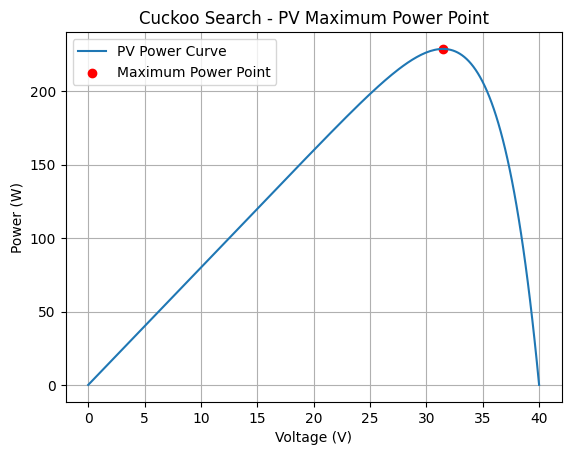

In [10]:
#PROBLEM 6 : CUCKOO SEARCH USING PHOTOVOLTAIC
import numpy as np
import random
import math
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

Isc = 8.0
Voc = 40.0

def power(v):
    current = Isc * (1 - (v / Voc) ** 10)
    return v * max(0, current)

n = 20
pa = 0.25
iterations = 10
alpha = 0.1
beta = 1.5

sigma = (math.gamma(1 + beta) * math.sin(math.pi * beta / 2) /
         (math.gamma((1 + beta) / 2) * beta *
          2 ** ((beta - 1) / 2))) ** (1 / beta)

nests = np.random.uniform(0, Voc, n)

best = nests[np.argmax([power(x) for x in nests])]

print("CUCKOO SEARCH USING PHOTOVOLTAIC")
print("--------------------------------")

for it in range(iterations):

    for i in range(n):

        u = np.random.normal(0, sigma)
        v = np.random.normal(0, 1)

        levy = u / (abs(v) ** (1 / beta) + 1e-12)

        new = nests[i] + alpha * levy * np.random.normal()
        new = np.clip(new, 0, Voc)

        j = random.randrange(n)

        if power(new) > power(nests[j]):
            nests[j] = new

    worst = np.argsort([power(x) for x in nests])[:int(pa * n)]

    nests[worst] = np.random.uniform(0, Voc, len(worst))

    current_best = nests[np.argmax([power(x) for x in nests])]

    if power(current_best) > power(best):
        best = current_best

    print("Iteration:", it + 1,
          "| Voltage:", round(best, 2),
          "| Power:", round(power(best), 2))

best_current = Isc * (1 - (best / Voc) ** 10)
best_power = power(best)

print("\nFINAL MPP RESULT")
print("Best Voltage:", round(best, 2), "V")
print("Best Current:", round(best_current, 2), "A")
print("Maximum Power:", round(best_power, 2), "W")

voltage = np.linspace(0, Voc, 200)
power_values = [power(v) for v in voltage]

plt.plot(voltage, power_values, label="PV Power Curve")
plt.scatter(best, best_power, color="red",
            label="Maximum Power Point")

plt.xlabel("Voltage (V)")
plt.ylabel("Power (W)")
plt.title("Cuckoo Search - PV Maximum Power Point")
plt.legend()
plt.grid()
plt.show()


In [11]:
#PROBLEM 7 : OPTIMIZATION VIA GENE EXPRESSION ALGORITHM
import random

random.seed(1)

n = 6
length = 5
generations = 10
mutation_rate = 0.05

def express(chromosome):
    return int("".join(map(str, chromosome)), 2)

def fitness(chromosome):
    x = express(chromosome)
    return 1 / (1 + (x - 10) ** 2)

population = [[random.randint(0, 1) for j in range(length)] for i in range(n)]

for g in range(generations):
    population = sorted(population, key=fitness, reverse=True)

    best = population[0]
    print("Generation", g + 1, "Best x:", express(best),
          "Fitness:", round(fitness(best), 4))

    parents = population[:3]
    new_population = parents[:]

    while len(new_population) < n:
        p1 = random.choice(parents)
        p2 = random.choice(parents)

        point = random.randint(1, length - 1)
        child = p1[:point] + p2[point:]

        for j in range(length):
            if random.random() < mutation_rate:
                child[j] = 1 - child[j]

        new_population.append(child)

    population = new_population

best = max(population, key=fitness)

print("Best Solution:", express(best))
print("Best Fitness:", round(fitness(best), 4))


Generation 1 Best x: 9 Fitness: 0.5
Generation 2 Best x: 9 Fitness: 0.5
Generation 3 Best x: 9 Fitness: 0.5
Generation 4 Best x: 9 Fitness: 0.5
Generation 5 Best x: 9 Fitness: 0.5
Generation 6 Best x: 10 Fitness: 1.0
Generation 7 Best x: 10 Fitness: 1.0
Generation 8 Best x: 10 Fitness: 1.0
Generation 9 Best x: 10 Fitness: 1.0
Generation 10 Best x: 10 Fitness: 1.0
Best Solution: 10
Best Fitness: 1.0
